# Todos los tópicos: nombre del LLM, tamaño y sentimiento

Apoyo para la sección 4.3 del reporte. Esta libreta lee la exportación **20261107T183230432171Z** del recorrido paso a paso, verifica sus hashes y combina nombres del LLM con predicciones de sentimiento por reseña. No entrena modelos ni solicita interpretaciones nuevas.

Son **18 tópicos base (0–17) y 28 alternativos (0–27)**. −1 identifica reseñas sin tópico y no es un grupo interpretado. Cada sistema se ordena por tamaño; las filas de ambos paneles no son parejas de temas. Los nombres son respuestas guardadas del LLM, no etiquetas humanas validadas.

In [1]:
from pathlib import Path
import hashlib, json, textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/difusion.sh').exists())
ROOT = REPO/'reports/drafts/difusion'
SOURCE = ROOT/'exports/pipeline-base-alternativa-paso-a-paso/20261107T183230432171Z'
def digest(p): return hashlib.sha256(p.read_bytes()).hexdigest()
assert digest(SOURCE/'manifest.json') == 'd5d91f8b7bdea890ae24a06147b3f21ca82d59f41a28b0dd1319c35eacbe8168'
manifest = json.loads((SOURCE/'manifest.json').read_text())
SYSTEMS = ['base', 'alternative']
LABELS = ['negative', 'neutral', 'positive']
COLORS = ['#BC5051', '#A8AFB8', '#468C73']
NAMES = ['Negativo', 'Neutral', 'Positivo']
tables, summary, input_hashes = {}, [], {}
for system in SYSTEMS:
    paths = [SOURCE/f'{system}-topicos-palabras-llm.csv', SOURCE/f'{system}-asignaciones.csv']
    for p in paths:
        assert digest(p) == manifest['files'][p.name]
        input_hashes[p.name] = digest(p)
    topics, rows = [pd.read_csv(p) for p in paths]
    assert rows.record_id.is_unique
    assert set(rows.model_label) <= set(LABELS)
    topics = topics.loc[topics.topic_id.ge(0)].copy()
    assert topics.topic_id.is_unique and topics.name.notna().all()
    counts = pd.crosstab(rows.topic_id, rows.model_label).reindex(columns=LABELS, fill_value=0)
    topic = topics.merge(counts, left_on='topic_id', right_index=True, validate='one_to_one')
    assert (topic[LABELS].sum(axis=1) == topic['size']).all()
    topic = topic.sort_values(['size','topic_id'], ascending=[False,True]).reset_index(drop=True)
    expected = 18 if system=='base' else 28
    assert set(topic.topic_id) == set(range(expected))
    assigned = int(topic['size'].sum()); unassigned = int(rows.topic_id.eq(-1).sum())
    assert assigned + unassigned == len(rows)
    tables[system] = topic
    summary.append(dict(system=system,topics=len(topic),rows=len(rows),assigned=assigned,
                        unassigned=unassigned,coverage_pct=assigned/len(rows)*100))
summary = pd.DataFrame(summary).set_index('system')
display(summary)


,topics,rows,assigned,unassigned,coverage_pct
system,,,,,
base,18,1000,953,47,95.300000
alternative,28,987,846,141,85.714286


## Figura: todos los nombres, todos los grupos

La longitud total muestra el número de reseñas; los segmentos muestran sus predicciones de sentimiento. Se conserva una **escala lineal común**: el grupo base de 529 reseñas sigue siendo visualmente mayor que cualquier grupo alternativo. Los números al final de las barras permiten leer los grupos pequeños. Los nombres completos se distribuyen en líneas encima de cada barra.

Las barras cubren 953/1.000 reseñas base y 846/987 alternativas: el 100 % de las que recibieron tópico. El sentimiento corresponde al comentario completo, no a cada aspecto mencionado ni a la opinión del LLM.

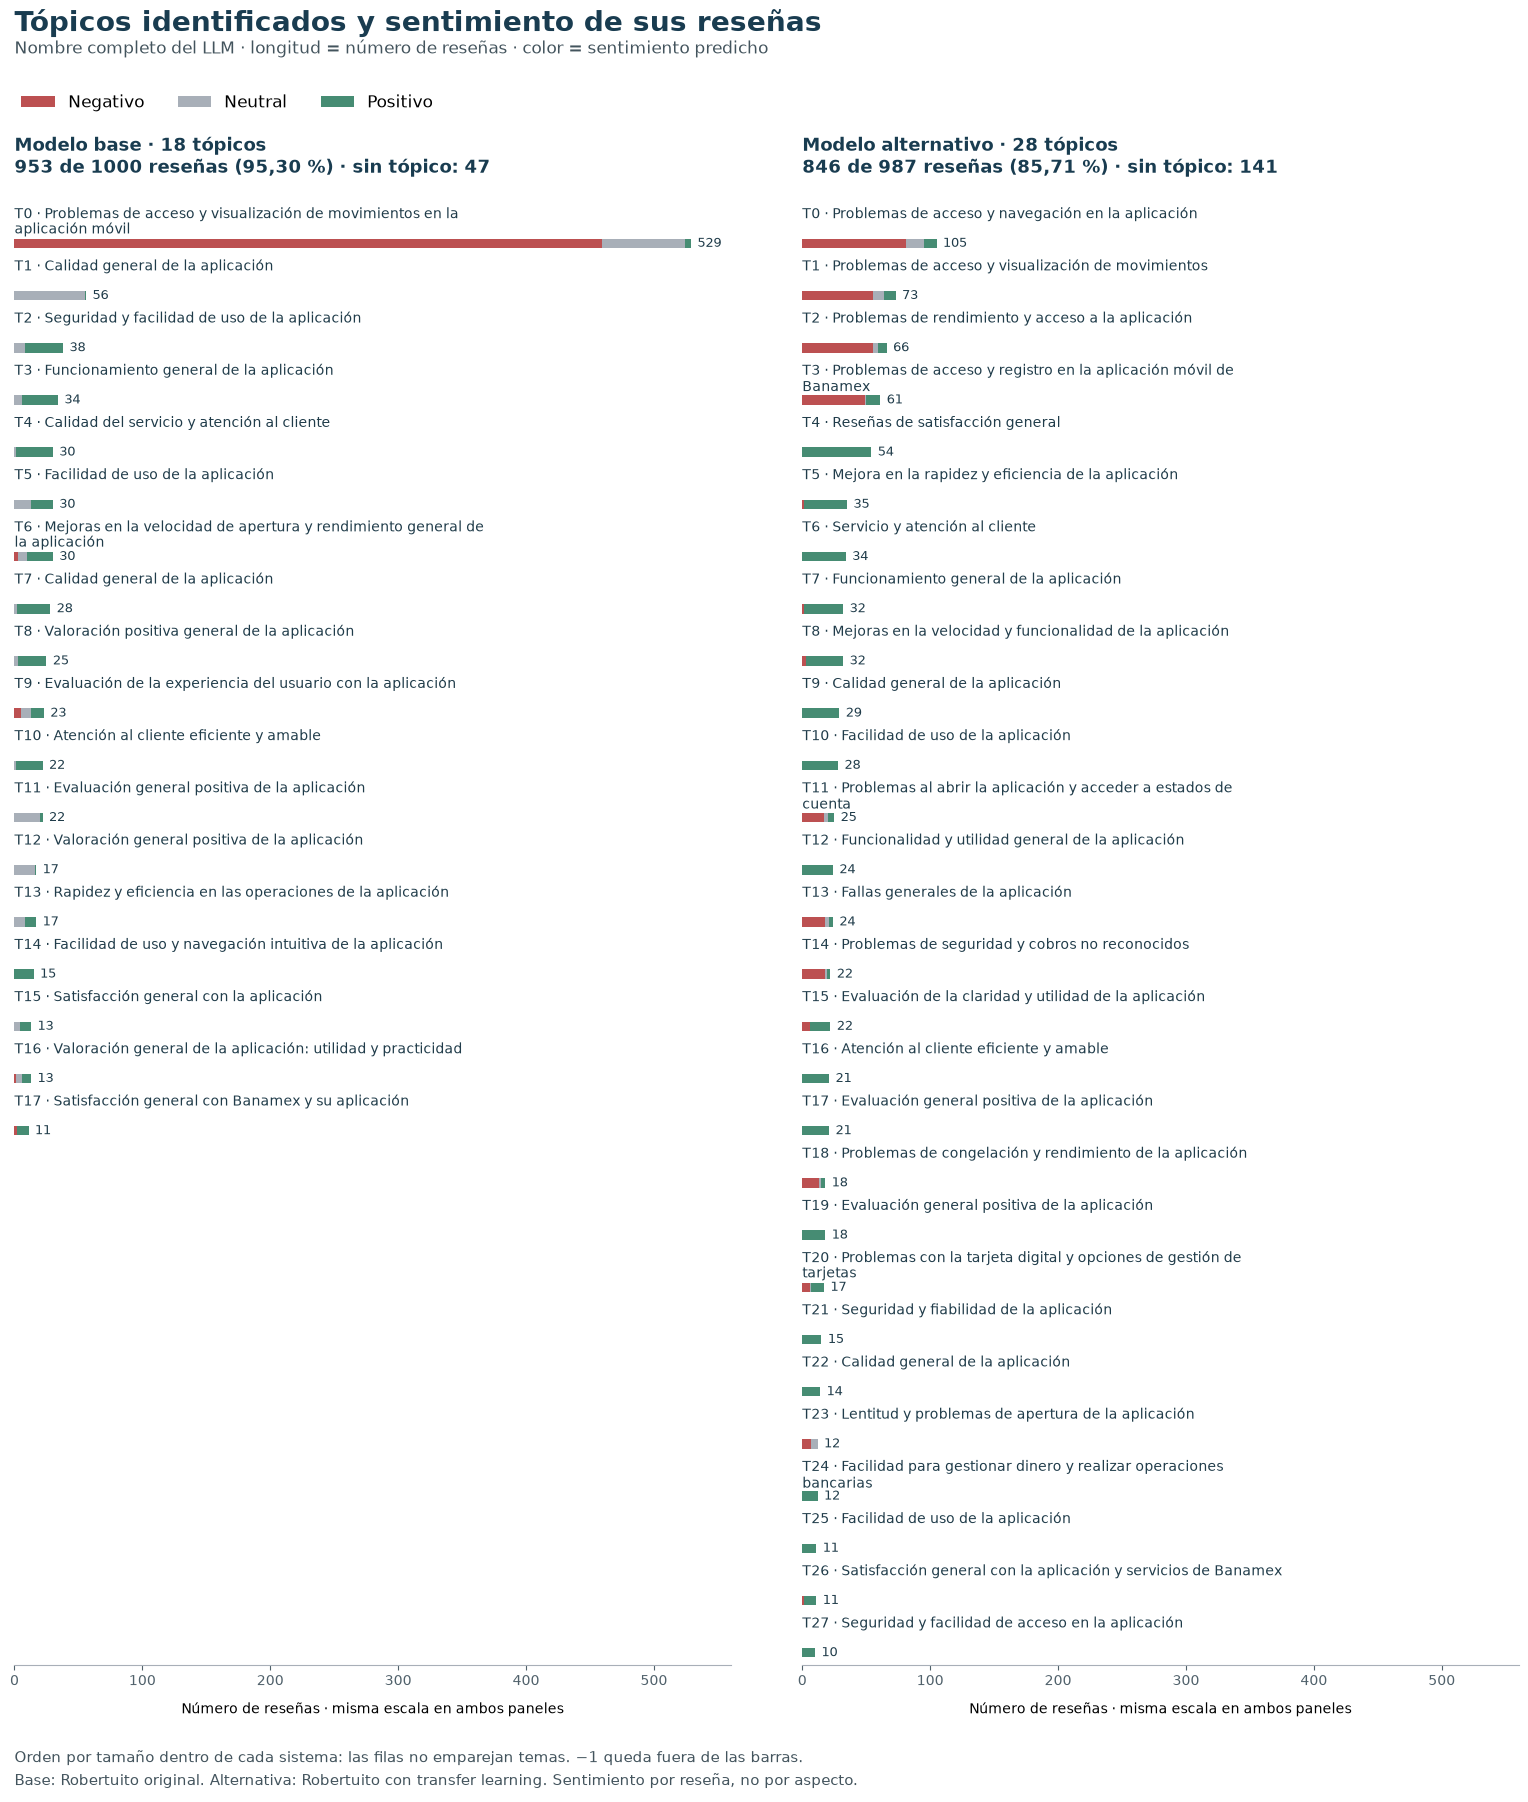

In [2]:
plt.rcParams.update({'font.family':'DejaVu Sans', 'svg.fonttype':'none'})
fig, axes = plt.subplots(1, 2, figsize=(16, 18.5), sharex=True)
fig.subplots_adjust(left=.035, right=.975, top=.88, bottom=.09, wspace=.10)
fig.suptitle('Tópicos identificados y sentimiento de sus reseñas', x=.035, ha='left', y=.985, fontsize=20, fontweight='bold', color='#193C50')
fig.text(.035, .961, 'Nombre completo del LLM · longitud = número de reseñas · color = sentimiento predicho', fontsize=12, color='#43545D')
fig.legend([Patch(facecolor=c) for c in COLORS], NAMES, loc='upper left', bbox_to_anchor=(.03,.947), frameon=False, ncol=3, fontsize=12)
max_rows = max(len(t) for t in tables.values())
for ax, system, title in zip(axes, SYSTEMS, ['Modelo base', 'Modelo alternativo']):
    topic = tables[system]; stats = summary.loc[system]
    coverage = f"{stats.coverage_pct:.2f}".replace('.', ',')
    ax.set_title(f"{title} · {len(topic)} tópicos\n{int(stats.assigned)} de {int(stats.rows)} reseñas ({coverage} %) · sin tópico: {int(stats.unassigned)}",
                 loc='left', fontsize=13, pad=22, fontweight='bold', color='#193C50')
    for i, row in enumerate(topic.itertuples()):
        y = i*1.6
        label = f"T{row.topic_id} · {row.name}"
        wrapped = textwrap.fill(label, width=67, break_long_words=False, break_on_hyphens=False)
        assert len(wrapped.splitlines()) <= 3
        ax.text(0, y, wrapped, fontsize=10, va='top', ha='left', linespacing=1.1, color='#203C4A')
        bar_y = y + 1.13
        left = 0
        for sentiment, color in zip(LABELS, COLORS):
            value = int(getattr(row, sentiment))
            ax.barh(bar_y, value, left=left, height=.29, color=color, zorder=3)
            left += value
        ax.text(left+5, bar_y, str(row.size), fontsize=9.5, va='center', color='#203C4A')
    ax.set_xlim(0,560);ax.set_ylim(max_rows*1.6-.1,-.1)
    ax.set_xticks([0,100,200,300,400,500]); ax.set_yticks([])
    ax.set_xlabel('Número de reseñas · misma escala en ambos paneles', fontsize=10, labelpad=10)
    ax.tick_params(axis='x', colors='#50616B')
    for side in ['top','left','right']: ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color('#A8AFB8')
fig.text(.035,.025,'Orden por tamaño dentro de cada sistema: las filas no emparejan temas. −1 queda fuera de las barras.\nBase: Robertuito original. Alternativa: Robertuito con transfer learning. Sentimiento por reseña, no por aspecto.',fontsize=11,color='#43545D',linespacing=1.5)
display(fig)
plt.close(fig)


## Datos y exportación reproducible

La tabla permite consultar el número exacto de reseñas negativas, neutrales y positivas detrás de cada barra. Las categorías del LLM también se conservan, aunque no se usan como colores: una clasificación `single_feature` no demuestra calidad temática. Esta figura usa las interpretaciones de la reproducción paso a paso, cuya procedencia y reutilización de respuestas se documentan en su exportación.

La salida incluye SVG ampliable, PNG, PDF y CSV. El PDF exportado es **solo la figura**; esta libreta no modifica el PDF del reporte.

## Distribución de tamaños en dos paneles

El modelo base aparece en azul a la izquierda y el alternativo en naranja a la derecha. Ambos paneles comparten la escala vertical. Las posiciones indican el orden por tamaño, no una correspondencia entre temas. Se excluyen las reseñas sin tópico. Esta comparación muestra concentración, no calidad temática.


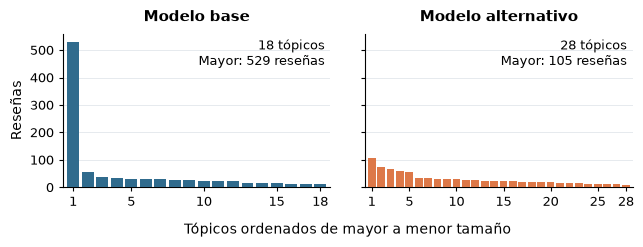

In [3]:
rank_fig, rank_axes = plt.subplots(1, 2, figsize=(6.4, 2.65), sharey=True)
rank_fig.subplots_adjust(left=.095, right=.985, bottom=.23, top=.81, wspace=.13)
rank_colors = {'base':'#306B8D', 'alternative':'#DD7848'}
rank_rows = []
for ax, system, title in zip(rank_axes, SYSTEMS, ['Modelo base', 'Modelo alternativo']):
    values = tables[system].sort_values(['size','topic_id'], ascending=[False,True])
    ranks = np.arange(1, len(values)+1)
    ax.bar(ranks, values['size'], width=.82, color=rank_colors[system], zorder=3)
    ax.set_title(title, fontsize=11, pad=9, fontweight='bold')
    ax.text(.98, .97, f"{len(values)} tópicos\nMayor: {int(values['size'].max())} reseñas", transform=ax.transAxes,
            ha='right', va='top', fontsize=9)
    ticks = [1,5,10,15,18] if system == 'base' else [1,5,10,15,20,25,28]
    ax.set(xlim=(.3,len(values)+.7), ylim=(0,560), xticks=ticks, yticks=[0,100,200,300,400,500])
    ax.tick_params(labelsize=9, length=3)
    ax.grid(axis='y', color='#E2E7EB', linewidth=.6, zorder=0)
    ax.spines[['top','right']].set_visible(False)
    rank_rows.extend(dict(system=system,rank=int(rank),topic_id=int(row.topic_id),size=int(row.size))
                     for rank,row in zip(ranks,values.itertuples()))
rank_axes[0].set_ylabel('Reseñas', fontsize=10)
rank_fig.text(.54, .055, 'Tópicos ordenados de mayor a menor tamaño', ha='center', fontsize=10)
rank_table = pd.DataFrame(rank_rows)
assert rank_table.groupby('system')['size'].sum().to_dict()=={'alternative':846,'base':953}
display(rank_fig)
plt.close(rank_fig)


In [4]:
from datetime import datetime, timezone
from importlib.metadata import version
combined = pd.concat([t.assign(system=s) for s,t in tables.items()], ignore_index=True)
display(combined[['system','topic_id','name','size',*LABELS]])
OUT = ROOT/'exports/topicos-y-sentimiento-seccion-4'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT.mkdir(parents=True, exist_ok=False)
for ext in ['svg','png','pdf']:
    fig.savefig(OUT/f'topicos-llm-sentimiento-completo.{ext}', dpi=160, facecolor='white')
for ext in ['svg','png','pdf']:
    rank_fig.savefig(OUT/f'distribucion-tamanos-combinada.{ext}', dpi=180, facecolor='white')
rank_table.to_csv(OUT/'distribucion-tamanos-combinada.csv', index=False)
combined.to_csv(OUT/'topicos-llm-sentimiento-completo.csv', index=False)
summary.to_csv(OUT/'cobertura.csv')
nb_path = ROOT/'topicos-y-sentimiento-seccion-4.ipynb'
nb = json.loads(nb_path.read_text())
receipt = {'source_directory':str(SOURCE.relative_to(ROOT)), 'source_manifest_sha256':digest(SOURCE/'manifest.json'),
 'input_hashes':input_hashes,'new_model_fits':0,'new_provider_requests':0,
 'notebook':nb_path.name,'cell_sources_sha256':hashlib.sha256('\n'.join(''.join(c['source']) for c in nb['cells']).encode()).hexdigest(),
 'software':{p:version(p) for p in ['pandas','matplotlib','numpy']},'files':{p.name:digest(p) for p in OUT.iterdir()}}
(OUT/'manifest.json').write_text(json.dumps(receipt, ensure_ascii=False, indent=2)+'\n')
(OUT.parent/'latest.json').write_text(json.dumps({'directory':str(OUT.relative_to(ROOT)), 'manifest_sha256':digest(OUT/'manifest.json')},indent=2)+'\n')
plt.close(fig)
print('Evidencia exportada:', OUT)
print('Nuevos ajustes: 0 · solicitudes al LLM: 0')


,system,topic_id,name,size,negative,neutral,positive
0,base,0,Problemas de acceso y visualización de movimie...,529,459,65,5
1,base,1,Calidad general de la aplicación,56,0,55,1
2,base,2,Seguridad y facilidad de uso de la aplicación,38,0,8,30
3,base,3,Funcionamiento general de la aplicación,34,0,6,28
4,base,4,Calidad del servicio y atención al cliente,30,0,1,29
5,base,5,Facilidad de uso de la aplicación,30,0,13,17
6,base,6,Mejoras en la velocidad de apertura y rendimie...,30,3,7,20
7,base,7,Calidad general de la aplicación,28,0,2,26
8,base,8,Valoración positiva general de la aplicación,25,0,3,22
9,base,9,Evaluación de la experiencia del usuario con l...,23,5,8,10


Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/exports/topicos-y-sentimiento-seccion-4/20261108T184953408091Z
Nuevos ajustes: 0 · solicitudes al LLM: 0
